# 02. Análisis Cuantitativo Profundo: Propiedades Estadísticas
Este notebook aplica econometría financiera sobre los activos del mercado español.
El objetivo es diagnosticar el comportamiento estocástico de las series temporales para encontrar ventajas matemáticas explotables en el concurso BME.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# 1. Cargar Datos
prices = pd.read_csv("../data/raw/stocks_close_15y.csv", index_col=0, parse_dates=True)
volumes = pd.read_csv("../data/raw/stocks_volume_15y.csv", index_col=0, parse_dates=True)

# Cálculo de Log-Retornos (Requerido para cálculo estocástico)
log_returns = np.log(prices / prices.shift(1)).dropna(how='all')
euro_volume = prices * volumes

# Filtramos a las últimas 1000 sesiones (~4 años) para el análisis estadístico moderno
log_returns = log_returns.tail(1000)
euro_volume = euro_volume.tail(1000)

print(f"Datos cargados: {log_returns.shape[0]} sesiones.")

Datos cargados: 1000 sesiones.


## 1. Normalidad, Riesgo de Cola y "Fat Tails"
En la teoría financiera clásica se asume que los retornos son normales. Si en el IBEX los retornos tienen exceso de curtosis (Fat Tails), significa que los eventos extremos ocurren con mucha mayor frecuencia. Esto destruye los Stop-Loss estáticos por "gaps" de apertura.

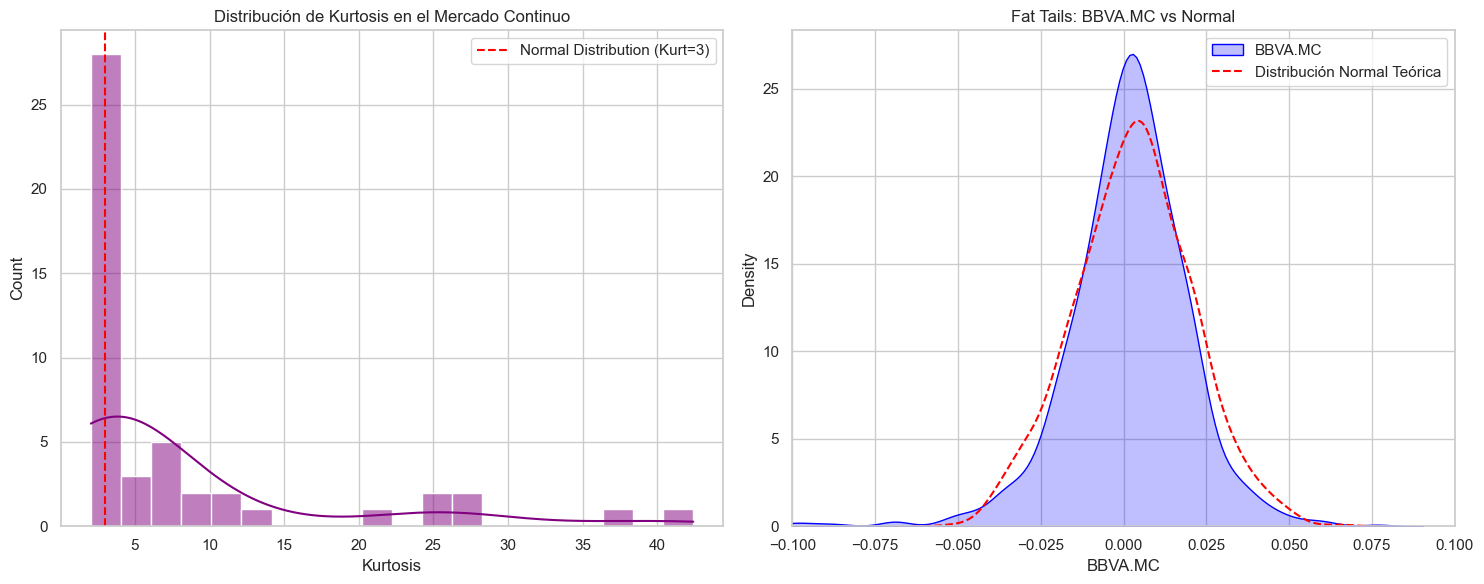

Interpretación Algorítmica:
La vasta mayoría del mercado español tiene una Kurtosis masiva (> 3). El mercado NO es normal.
Consecuencia: Modelos predictivos basados en Varianza tradicional subestimarán drásticamente el riesgo de un colapso.


In [2]:
# Cálculo de Kurtosis y Skewness
stats_df = pd.DataFrame({
    'Mean': log_returns.mean() * 252, # Anualizado
    'Vol': log_returns.std() * np.sqrt(252),
    'Skewness': log_returns.skew(),
    'Kurtosis': log_returns.kurtosis() # > 3 indica Fat Tails (Leptocúrtica)
}).dropna()

# Visualización del Riesgo de Cola
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histograma de Curtosis
sns.histplot(stats_df['Kurtosis'], bins=20, kde=True, ax=axes[0], color='purple')
axes[0].set_title('Distribución de Kurtosis en el Mercado Continuo')
axes[0].axvline(3, color='red', linestyle='--', label='Normal Distribution (Kurt=3)')
axes[0].legend()

# Comparación Visual (BBVA vs Normal)
sample_ticker = 'BBVA.MC'
if sample_ticker in log_returns.columns:
    sample_rets = log_returns[sample_ticker].dropna()
    sns.kdeplot(sample_rets, ax=axes[1], color='blue', label=sample_ticker, fill=True)
    
    # Simular normal con misma media y varianza
    normal_sim = np.random.normal(sample_rets.mean(), sample_rets.std(), len(sample_rets))
    sns.kdeplot(normal_sim, ax=axes[1], color='red', linestyle='--', label='Distribución Normal Teórica')
    
    axes[1].set_title(f"Fat Tails: {sample_ticker} vs Normal")
    axes[1].set_xlim(-0.1, 0.1)
    axes[1].legend()

plt.tight_layout()
plt.show()

print("Interpretación Algorítmica:")
print("La vasta mayoría del mercado español tiene una Kurtosis masiva (> 3). El mercado NO es normal.")
print("Consecuencia: Modelos predictivos basados en Varianza tradicional subestimarán drásticamente el riesgo de un colapso.")

## 2. Memoria del Mercado (Exponente de Hurst y Mean-Reversion)
¿El mercado español es de tendencia (Trending) o de reversión a la media (Mean-Reverting)?
*   **H = 0.5**: Paseo Aleatorio (Ruido Blanco).
*   **H < 0.5**: Reversión a la Media (Ideal para RSI, Bandas Bollinger).
*   **H > 0.5**: Persistencia / Tendencia (Ideal para Breakouts, Medias Móviles).

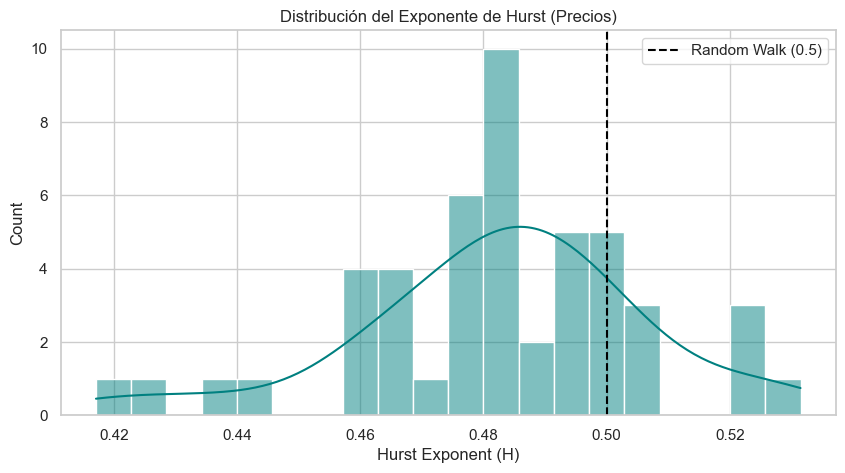

Top 5 Activos más Mean-Reverting (H < 0.5): ['PUIG.MC', 'VIS.MC', 'ANE.MC', 'CABK.MC', 'RED.MC']
Top 5 Activos más Trending (H > 0.5): ['MRL.MC', 'IAG.MC', 'ENC.MC', 'CASH.MC', 'PHM.MC']

Implicación para el Concurso:
Debes aplicar sistemas antitendenciales en los valores del lado izquierdo y sistemas de Momentum en el lado derecho.


In [3]:
# Función para calcular el Exponente de Hurst aproximado
def get_hurst(ts, max_lag=20):
    lags = range(2, max_lag)
    tau = [np.sqrt(np.std(np.subtract(ts[lag:], ts[:-lag]))) for lag in lags]
    poly = np.polyfit(np.log(lags), np.log(tau), 1)
    return poly[0]*2.0

hurst_exponents = {}
for col in log_returns.columns:
    ts = prices[col].dropna().values
    if len(ts) > 500:
        hurst_exponents[col] = get_hurst(ts)

hurst_df = pd.Series(hurst_exponents).sort_values()

plt.figure(figsize=(10, 5))
sns.histplot(hurst_df, bins=20, kde=True, color='teal')
plt.axvline(0.5, color='black', linestyle='--', label='Random Walk (0.5)')
plt.title("Distribución del Exponente de Hurst (Precios)")
plt.xlabel("Hurst Exponent (H)")
plt.legend()
plt.show()

print("Top 5 Activos más Mean-Reverting (H < 0.5):", hurst_df.head(5).index.tolist())
print("Top 5 Activos más Trending (H > 0.5):", hurst_df.tail(5).index.tolist())
print("\nImplicación para el Concurso:")
print("Debes aplicar sistemas antitendenciales en los valores del lado izquierdo y sistemas de Momentum en el lado derecho.")

## 3. Autocorrelación de 1er y 2do Orden (Short-Term Memory)
En lugar de mirar un solo activo, vamos a escanear todo el mercado para medir el Lag 1 (Ayer vs Hoy) y Lag 2 (Anteayer vs Hoy).
*   **ACF Lag 1 < 0:** Reversión violenta (lo que sube un día, baja al siguiente).
*   **ACF Lag 1 > 0:** Momentum a muy corto plazo.

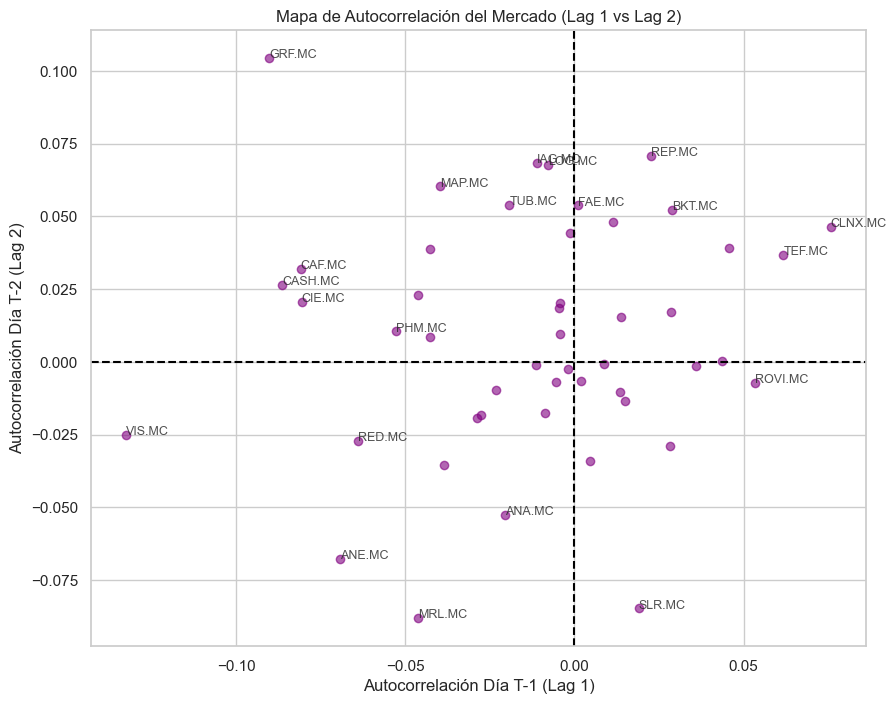

Implicación:
Cuadrante Inferior Izquierdo (Lag 1 < 0, Lag 2 < 0): Altamente Mean-Reverting. Comprar tras caídas.
Cuadrante Superior Derecho (Lag 1 > 0, Lag 2 > 0): Momentum persistente. Seguir la tendencia.


In [4]:
acf_data = []
for col in log_returns.columns:
    ts = log_returns[col].dropna()
    if len(ts) > 100:
        # Calcular autocorrelación para Lag 1 y Lag 2
        lag1 = ts.autocorr(lag=1)
        lag2 = ts.autocorr(lag=2)
        acf_data.append({'Ticker': col, 'ACF_Lag1': lag1, 'ACF_Lag2': lag2})

acf_df = pd.DataFrame(acf_data).set_index('Ticker')

plt.figure(figsize=(10, 8))
plt.scatter(acf_df['ACF_Lag1'], acf_df['ACF_Lag2'], color='purple', alpha=0.6)
plt.axhline(0, color='black', linestyle='--')
plt.axvline(0, color='black', linestyle='--')

# Anotaciones
for idx, row in acf_df.iterrows():
    if abs(row['ACF_Lag1']) > 0.05 or abs(row['ACF_Lag2']) > 0.05:
        plt.annotate(idx, (row['ACF_Lag1'], row['ACF_Lag2']), fontsize=9, alpha=0.8)

plt.title("Mapa de Autocorrelación del Mercado (Lag 1 vs Lag 2)")
plt.xlabel("Autocorrelación Día T-1 (Lag 1)")
plt.ylabel("Autocorrelación Día T-2 (Lag 2)")
plt.show()

print("Implicación:")
print("Cuadrante Inferior Izquierdo (Lag 1 < 0, Lag 2 < 0): Altamente Mean-Reverting. Comprar tras caídas.")
print("Cuadrante Superior Derecho (Lag 1 > 0, Lag 2 > 0): Momentum persistente. Seguir la tendencia.")

## 4. Matriz de Personalidad Matemática (Exportación)
Unimos todas las métricas (Kurtosis, Hurst, ACF) en una tabla unificada y la guardamos para tomar decisiones finales en el Notebook 03.

In [5]:
# Consolidamos los datos calculados en las celdas anteriores
master_df = pd.concat([stats_df, hurst_df.rename('Hurst'), acf_df], axis=1).dropna()

# Guardamos el archivo para el Notebook 03
master_df.to_csv("../data/raw/quant_personality.csv")

print("Matriz de Personalidad guardada con éxito. Variables incluidas:")
display(master_df.head())

Matriz de Personalidad guardada con éxito. Variables incluidas:


,Mean,Vol,Skewness,Kurtosis,Hurst,ACF_Lag1,ACF_Lag2
PUIG.MC,-0.133953,0.323109,-0.680622,11.357437,0.417108,0.015038,-0.013608
ROVI.MC,0.058991,0.305198,-2.602071,21.536133,0.491850,0.053422,-0.007236
MAP.MC,0.221773,0.206431,-0.737624,6.355890,0.492265,-0.039776,0.060321
MRL.MC,0.084500,0.239602,-0.082634,2.075867,0.508046,-0.046186,-0.088097
FAE.MC,0.059956,0.188698,0.290975,7.875948,0.494727,0.001068,0.053730
